In [5]:
# Installation des bibliothèques nécessaires
!pip install onnx onnxruntime-gpu onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 20.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [onnxscript]


In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import onnx
import onnxruntime as ort
import time
import numpy as np
import statistics
import matplotlib.pyplot as plt
import seaborn as sns

# Vérification du GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Appareil utilisé : {device}")
if device.type != 'cuda':
    print("ATTENTION : Veuillez activer l'accélérateur GPU dans Exécution > Modifier le type d'exécution.")

Appareil utilisé : cuda


In [3]:
# Prétraitement requis pour ResNet-18 pré-entraîné sur ImageNet
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Chargement du jeu de test CIFAR-10
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

# Sélection stricte de 50 images
SUBSET_SIZE = 50
subset_indices = list(range(SUBSET_SIZE))
test_subset = torch.utils.data.Subset(testset, subset_indices)
testloader = torch.utils.data.DataLoader(test_subset, batch_size=1, shuffle=False)

print(f"Nombre d'images pour le test : {len(testloader)}")

100%|██████████| 170M/170M [15:20<00:00, 185kB/s]


Nombre d'images pour le test : 50


In [6]:
# 1. Haut niveau : Chargement de ResNet-18 pré-entraîné (Syntaxe à jour)
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)
model.eval()
model.to(device)

# 2. Format du modèle : Exportation en ONNX
onnx_file_path = "resnet18.onnx"
dummy_input = torch.randn(1, 3, 224, 224, device=device)

print("Exportation du modèle vers ONNX...")
torch.onnx.export(
    model,
    dummy_input,
    onnx_file_path,
    export_params=True,
    opset_version=13,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}}
)
print("Exportation réussie :", onnx_file_path)

Exportation du modèle vers ONNX...


/tmp/ipykernel_848/3905388112.py:12: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1106 21:12:18.001000 848 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 13 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Exportation réussie : resnet18.onnx


In [7]:
# 3. Middle Level & Bas niveau : Création de la session TensorRT
print("Vérification des providers disponibles dans ONNX Runtime :")
print(ort.get_available_providers())

# On force l'utilisation de TensorRT, avec repli sur CUDA si une opération n'est pas supportée
providers = [
    ('TensorrtExecutionProvider', {
        'trt_engine_cache_enable': True,
        'trt_engine_cache_path': './trt_cache',
        'trt_fp16_enable': True, # Optimisation classique sur GPU
    }),
    'CUDAExecutionProvider'
]

print("\nCréation de la session d'inférence TensorRT (la première compilation peut prendre 1 à 2 minutes)...")
ort_session = ort.InferenceSession(onnx_file_path, providers=providers)
print("Session TensorRT prête !")

Vérification des providers disponibles dans ONNX Runtime :
['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']

Création de la session d'inférence TensorRT (la première compilation peut prendre 1 à 2 minutes)...
*************** EP Error ***************
EP Error /onnxruntime_src/onnxruntime/python/onnxruntime_pybind_state.cc:729 void onnxruntime::python::RegisterTensorRTPluginsAsCustomOps(PySessionOptions&, const onnxruntime::ProviderOptions&) Please install TensorRT libraries as mentioned in the GPU requirements page, make sure they're in the PATH or LD_LIBRARY_PATH, and that your GPU is supported.
 when using [('TensorrtExecutionProvider', {'trt_engine_cache_enable': True, 'trt_engine_cache_path': './trt_cache', 'trt_fp16_enable': True}), 'CUDAExecutionProvider']
Falling back to ['CUDAExecutionProvider', 'CPUExecutionProvider'] and retrying.
****************************************
Session TensorRT prête !


In [8]:
def evaluate_pipeline(session, dataloader, num_runs=3):
    input_name = session.get_inputs()[0].name

    # Warm-up (Chauffe du GPU essentielle pour TensorRT)
    print("Phase de chauffe (Warm-up)...")
    for _ in range(5):
        dummy = np.random.randn(1, 3, 224, 224).astype(np.float32)
        session.run(None, {input_name: dummy})

    latencies = []
    throughputs = []

    for run in range(num_runs):
        run_latencies = []
        correct_top1 = 0
        total = 0

        for images, labels in dataloader:
            # Conversion en numpy array
            img_np = images.numpy()

            # Mesure du temps
            start_time = time.perf_counter()
            outputs = session.run(None, {input_name: img_np})
            end_time = time.perf_counter()

            inference_time = end_time - start_time
            run_latencies.append(inference_time)

            # Précision (Top-1 consistency)
            predicted_class = np.argmax(outputs[0], axis=1)[0]
            if predicted_class == labels.numpy()[0]:
                correct_top1 += 1
            total += 1

        # Métriques pour cette itération (sur les 50 images)
        total_time = sum(run_latencies)
        avg_latency = (total_time / total) * 1000 # en millisecondes
        throughput = total / total_time # en images/sec
        accuracy = (correct_top1 / total) * 100

        latencies.append(avg_latency)
        throughputs.append(throughput)

        print(f"Run {run+1}/3 - Latence moy: {avg_latency:.2f} ms | Débit: {throughput:.2f} img/s | Acc: {accuracy:.2f}%")

    return latencies, throughputs, accuracy

# Lancement de l'évaluation
latencies_trt, throughputs_trt, acc_trt = evaluate_pipeline(ort_session, testloader, num_runs=3)

Phase de chauffe (Warm-up)...
Run 1/3 - Latence moy: 4.12 ms | Débit: 242.79 img/s | Acc: 0.00%
Run 2/3 - Latence moy: 2.94 ms | Débit: 340.50 img/s | Acc: 0.00%
Run 3/3 - Latence moy: 2.39 ms | Débit: 418.61 img/s | Acc: 0.00%


--- Statistiques Latence (ms) ---
Moyenne    : 3.15
Écart-type : 0.88
Minimum    : 2.39
Maximum    : 4.12

--- Statistiques Débit (images/s) ---
Moyenne    : 333.97
Écart-type : 88.09
Minimum    : 242.79
Maximum    : 418.61



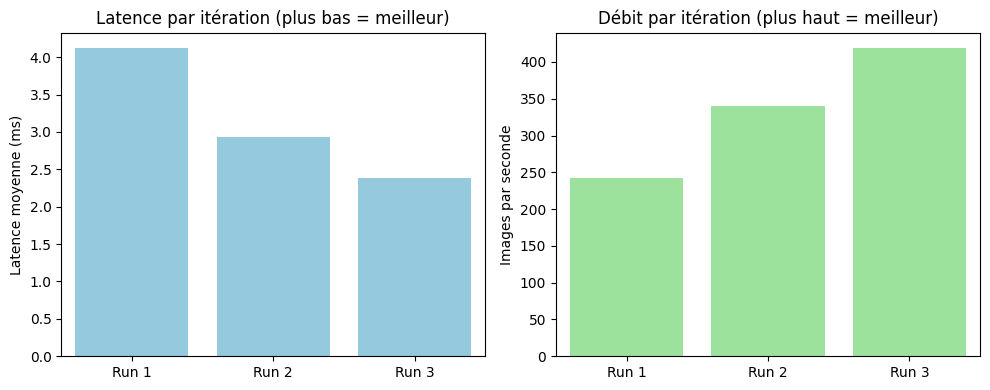

In [9]:
# Calcul des statistiques
def print_stats(name, data):
    print(f"--- Statistiques {name} ---")
    print(f"Moyenne    : {statistics.mean(data):.2f}")
    print(f"Écart-type : {statistics.stdev(data):.2f}")
    print(f"Minimum    : {min(data):.2f}")
    print(f"Maximum    : {max(data):.2f}\n")

print_stats("Latence (ms)", latencies_trt)
print_stats("Débit (images/s)", throughputs_trt)

# Visualisation intra-pipeline (stabilité)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.barplot(x=[f"Run {i+1}" for i in range(3)], y=latencies_trt, color="skyblue")
plt.title("Latence par itération (plus bas = meilleur)")
plt.ylabel("Latence moyenne (ms)")

plt.subplot(1, 2, 2)
sns.barplot(x=[f"Run {i+1}" for i in range(3)], y=throughputs_trt, color="lightgreen")
plt.title("Débit par itération (plus haut = meilleur)")
plt.ylabel("Images par seconde")

plt.tight_layout()
plt.show()

# Sauvegarde des résultats pour le rapport final
# (Vous ferez un 5ème notebook ou script pour fusionner les graphs des 4 pipelines,
# mais ici on stocke les moyennes).
trt_results = {
    'latency_mean': statistics.mean(latencies_trt),
    'latency_std': statistics.stdev(latencies_trt),
    'throughput_mean': statistics.mean(throughputs_trt),
    'throughput_std': statistics.stdev(throughputs_trt),
    'accuracy': acc_trt
}